<a href="https://colab.research.google.com/github/lalith-sky/fakenews/blob/main/fake_news_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/fake-and-real-news-dataset


In [ ]:
%pip install evaluate -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.2 MB/s eta 0:00:00


Using Colab cache for faster access to the 'fake-and-real-news-dataset' dataset.
Path to dataset files: /kaggle/input/fake-and-real-news-dataset
Accuracy: 98.81 %


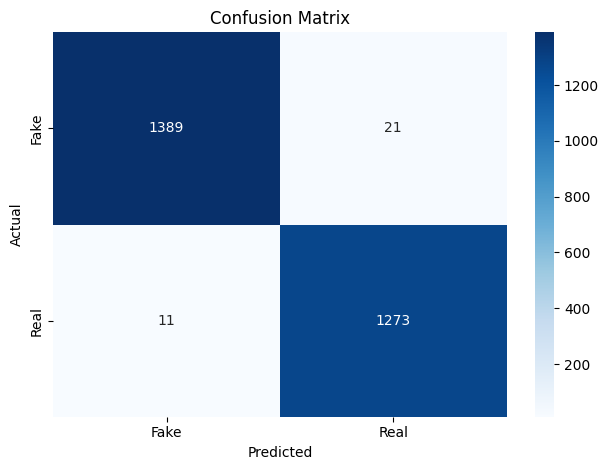


Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      1410
           1       0.98      0.99      0.99      1284

    accuracy                           0.99      2694
   macro avg       0.99      0.99      0.99      2694
weighted avg       0.99      0.99      0.99      2694



In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")
print("Path to dataset files:", path)

fake = pd.read_csv(f"{path}/Fake.csv")
true = pd.read_csv(f"{path}/True.csv")

fake["label"] = 0
true["label"] = 1

data = pd.concat([fake, true], axis=0)
data = data.sample(frac=0.15, random_state=42).reset_index(drop=True)

data = data.sample(frac=1, random_state=42)

X = data["text"]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42
)
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.95,
    max_features=100
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = PassiveAggressiveClassifier(max_iter=100, tol=1e-3)

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

score = accuracy_score(y_test, y_pred)
print("Accuracy:", round(score * 100, 2), "%")

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fake", "Real"],
            yticklabels=["Fake", "Real"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nClassification Report:\n", classification_report(y_test, y_pred))